### cities_10记录了十个沿海省份的经济指标，通过降维方法对各省、市经济发展情况

变量含义如下：

|变量|含义|
|:--:|:--:|
|AREA|地区|
|X1|GDP|
|X2|人均GDP|
|X3|工业增加值|
|X4|第三产业增加值|
|X5|固定资产投资|
|X6|基本建设投资|
|X7|社会消费品零售总额|
|X8|海关出口总额|
|X9|地方财政收入|

### 读取数据 -> 标准化 -> 因子分析

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from fa_kit import FactorAnalysis

#读取数据，中文编码`gbk`
cities = pd.read_csv("cities_10.csv", encoding='gbk')

# 学生标准化
scaler = StandardScaler()
scale_cities = scaler.fit_transform(cities.loc[:, 'X1':])

# 使用标准化后的数据进行因子分析
fa = FactorAnalysis.load_data_samples(
    scale_cities,
    preproc_demean=True,
    preproc_scale=True
)  
fa.extract_components()      #  提取因子
fa.find_comps_to_retain(method='top_n',num_keep=2)   # 保留2个因子
fa.rotate_components(method='varimax') #  最大方差因子旋转
fa_scores = fa.get_component_scores(scale_cities)    # 计算因子得分
# Equals to ```np.dot(scale_cities, fa_comps)```

### 连接因子得分与原始数据，根据业务理解为每个因子取名

In [2]:
# 将因子得分连接到原始数据集，并为每个因子命名
cities_factor_analysis = cities.join(
    pd.DataFrame(fa_scores, columns=['Gross', 'Avg']))
cities_factor_analysis.to_csv('cities_FA_score.csv', index=False)

### 层次聚类

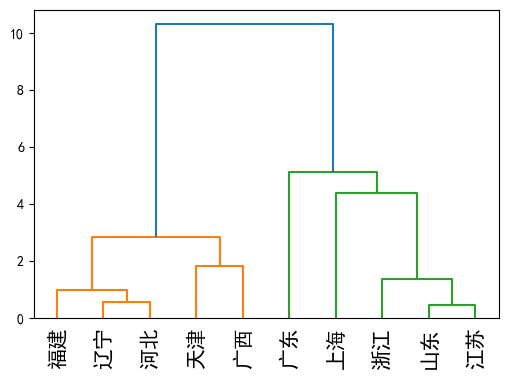

In [3]:
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt
from pylab import mpl

mpl.rcParams['font.sans-serif'] = ['SimHei'] # 指定默认字体
mpl.rcParams['axes.unicode_minus'] = False   # 解决保存图像是负号'-'显示为方块的问题

#  生成点与点之间的欧式距离矩阵
distMat = sch.distance.pdist(
    cities_factor_analysis[['Gross','Avg']],'euclidean') 

#  ward法进行层次聚类
Z = sch.linkage(distMat, method='ward') 

#  生成聚类树状图
fig, ax = plt.subplots(figsize=(6, 4)) 
P = sch.dendrogram(
    Z,                                               
    ax=ax,                                           # 设置绘制的轴
    labels=cities_factor_analysis['AREA'].tolist(),  # 设置标签
    leaf_font_size=15,                               # 设置标签字体大小
    leaf_rotation=90                                 # 设置标签字体方向
)  

plt.savefig('plot_dendrogram1.png')
plt.show()

### 选择簇数量，查看簇中心

In [4]:
#  根据聚类树状图，将样本聚为2个簇
labels = sch.cut_tree(Z, n_clusters=2)
cities_factor_analysis['cluster'] = labels

#  获取每个簇的中心
cities_factor_analysis.loc[:, 'X1':'X9'].groupby(
    cities_factor_analysis['cluster']).mean().T

cluster,0,1
X1,4138.96,9206.96
X2,12537.40,19653.40
X3,1003.96,3163.22
X4,1633.14,3686.52
X5,937.58,2379.68
X6,447.72,1089.48
X7,1571.38,3264.80
X8,94.82,610.84
X9,266.68,746.28
